# EDA Sample: Eras & Pace

**The question:** how has the way teams play changed, and why are scores so much higher now?

**The data:** `NBA_merged.csv`, built from the NBA API, 2014-15 through 2025-26. We also use your Basketball Reference file `per_game.csv` as an outside check.

**Note:** the NBA API file only goes back to 2014-15, so this notebook covers the three-point boom, not the league's full history.

**The six questions we ask of any new dataset:**

1. What does one row mean?
2. Is anything missing or broken?
3. What does each variable look like on its own?
4. How do groups or variables compare?
5. Does it change over time?
6. What should we ask next?

EDA is not about proving anything yet. The goal is to learn what the data can and can't tell us before we build on it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Colors used throughout, so "home" always looks the same from chart to chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, LIGHT_GRAY = "#0b0b0b", "#c3c2b7"

# Chart style. You only need to set this once per notebook.
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT_GRAY, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)

In [2]:
# If you run this in Colab, upload the files and remove the folder names from these paths
df = pd.read_csv("../Home Court Advantage/NBA_merged.csv", low_memory=False)
bbref = pd.read_csv("../Eras & Pace/per_game.csv")

print(df.shape)

(28878, 68)


## 1. What does one row mean?

In [3]:
df[["game_date", "season", "team_abbr", "opp_abbr", "PTS", "FG3A", "MIN", "possessions", "pace", "off_rating"]].head(4)

,game_date,season,team_abbr,opp_abbr,PTS,FG3A,MIN,possessions,pace,off_rating
0,2014-10-28,2014-15,ORL,NOP,84,11,240,96.44,96.44,87.100788
1,2014-10-28,2014-15,NOP,ORL,101,17,240,96.44,96.44,104.728328
2,2014-10-28,2014-15,DAL,SAS,100,21,240,88.20,88.20,113.378685
3,2014-10-28,2014-15,SAS,DAL,101,28,240,88.20,88.20,114.512472


In [4]:
print("Rows per game:", df.groupby("game_id").size().unique())
print("Does each game have one pace value?", (df.groupby("game_id")["pace"].nunique() == 1).all())
df.groupby("season")["game_id"].nunique()

Rows per game: [2]
Does each game have one pace value? True


season
2014-15    1230
2015-16    1230
2016-17    1230
2017-18    1230
2018-19    1230
2019-20    1059
2020-21    1080
2021-22    1230
2022-23    1230
2023-24    1230
2024-25    1230
2025-26    1230
Name: game_id, dtype: int64

**What to notice**

- One row is one team in one game, and both teams in a game share the same `pace`.
- 2019-20 and 2020-21 had fewer games, so we'll compare **per-game averages**, not season totals.

## 2. Is anything missing or broken?

In [5]:
missing = df.isna().sum()
print(missing[missing > 0])

# Do overtime games distort things?
df.groupby("ot_periods")[["MIN", "PTS", "possessions", "pace"]].mean().round(1)

FT_PCT          1
arena_state    36
dtype: int64


,MIN,PTS,possessions,pace
ot_periods,,,,
0,240.0,109.3,100.5,100.5
1,265.0,118.6,110.0,99.7
2,290.0,128.0,119.5,98.9
3,315.0,128.7,122.1,93.1
4,340.0,150.2,139.1,98.2


**What to notice**

- The only blanks are in columns we don't need here.
- Overtime adds to `PTS` and `possessions`, but `pace` stays level because it is adjusted to 48 minutes. **Always ask whether a stat is a raw count or adjusted for opportunity.**

A great check is to compare against an independent source. Let's see if our pace matches Basketball Reference.

In [6]:
league = df.groupby("season").agg(
    pace=("pace", "mean"), PTS=("PTS", "mean"), FG3A=("FG3A", "mean"),
    off_rating=("off_rating", "mean"), efg_pct=("efg_pct", "mean"),
)

check = league[["pace"]].join(bbref.set_index("Season")["Pace"].rename("bbref_pace"))
check["gap"] = check["pace"] - check["bbref_pace"]
check.round(2)

,pace,bbref_pace,gap
season,,,
2014-15,96.30,93.9,2.40
2015-16,98.09,95.8,2.29
2016-17,98.73,96.4,2.33
2017-18,99.57,97.3,2.27
2018-19,102.40,100.0,2.40
2019-20,102.70,100.3,2.40
2020-21,101.42,99.2,2.22
2021-22,100.58,98.2,2.38
2022-23,101.56,99.2,2.36


**What to notice**

- Our pace runs about 2 to 3 possessions higher than Basketball Reference every year.
- The cause is the formula. Our file uses the simple estimate, `FGA + 0.44*FTA - OREB + TOV`, and Basketball Reference uses a more detailed one.
- The gap is steady, so **trends are safe, but the exact numbers shouldn't be mixed between the two sources.** Off rating is affected too, since it divides by possessions.

## 3. What does one variable look like?

We'll compare the first and last seasons on the same axes.

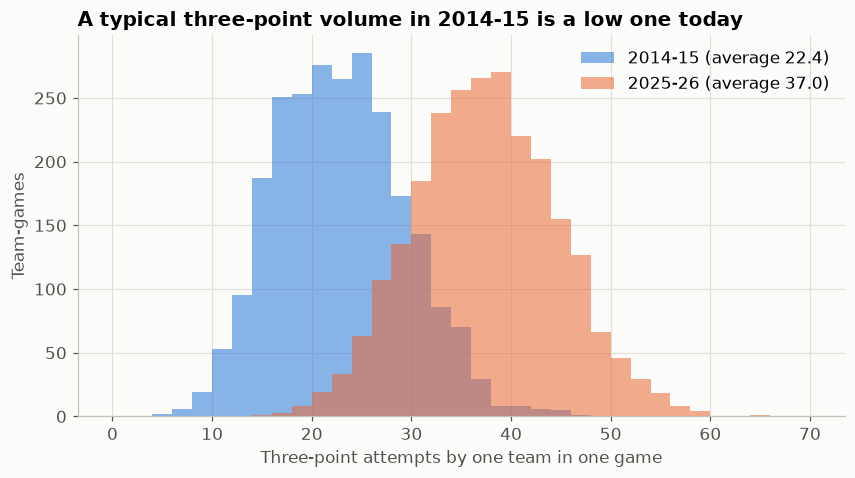

In [7]:
fig, ax = plt.subplots()
bins = range(0, 72, 2)

for season, color in [("2014-15", BLUE), ("2025-26", ORANGE)]:
    values = df.loc[df["season"] == season, "FG3A"]
    ax.hist(values, bins=bins, color=color, alpha=0.55, label=f"{season} (average {values.mean():.1f})")

ax.set_title("A typical three-point volume in 2014-15 is a low one today")
ax.set_xlabel("Three-point attempts by one team in one game")
ax.set_ylabel("Team-games")
ax.legend()
plt.show()

**What to notice**

- The whole distribution shifted right, so this wasn't a few teams pulling up the average.
- Teams averaged about 22 attempts a game in 2014-15 and about 37 in 2025-26.

## 4. Does it change over time?

These stats have different scales, so we use one small chart for each rather than forcing them onto a shared axis.

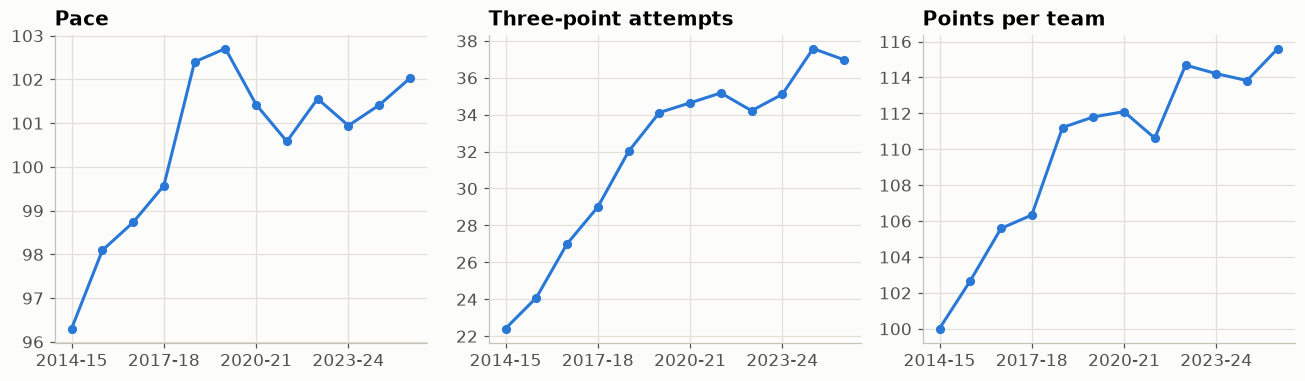

In [8]:
panels = [("pace", "Pace"), ("FG3A", "Three-point attempts"), ("PTS", "Points per team")]
seasons = list(league.index)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, title) in zip(axes, panels):
    ax.plot(seasons, league[col], color=BLUE, marker="o", markersize=5)
    ax.set_title(title)
    ax.set_xticks(range(0, 12, 3), seasons[::3])
plt.tight_layout()
plt.show()

**What to notice**

- Three-point attempts climbed steadily, and points rose with them.
- Pace jumped in 2018-19, and has been roughly flat since.
- These axes don't start at zero. That's fine for spotting a trend in a line chart, but compare the actual numbers before calling a change big.

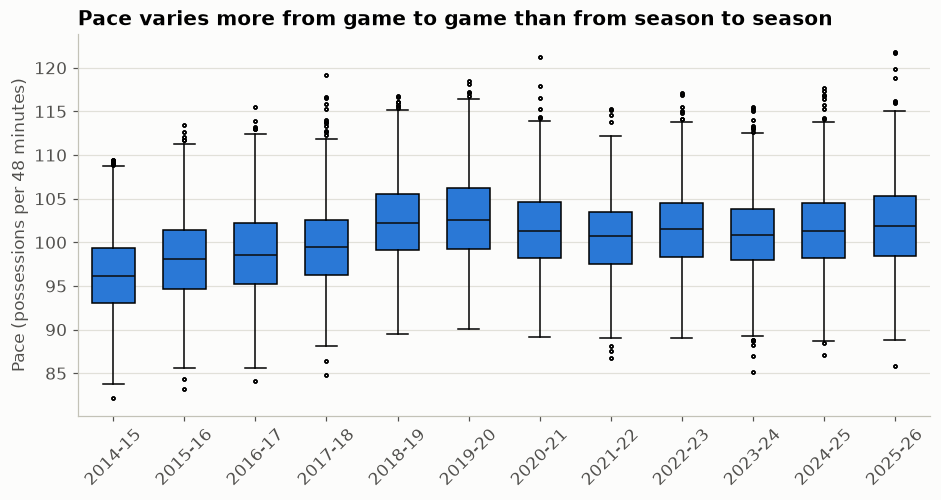

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([df.loc[df["season"] == s, "pace"] for s in seasons], patch_artist=True, widths=0.6,
           boxprops={"facecolor": BLUE}, medianprops={"color": INK}, flierprops={"markersize": 2})
ax.set_xticks(range(1, 13), seasons, rotation=45)
ax.set_ylabel("Pace (possessions per 48 minutes)")
ax.set_title("Pace varies more from game to game than from season to season")
ax.grid(axis="x", visible=False)
plt.show()

**What to notice**

- A line chart of averages hides how much single games differ. The boxes show that within any one season, games vary a lot.
- League-wide change is real, but a single game's pace tells you very little about its era.

## 5. Why are scores so much higher?

Points can rise for two reasons: more possessions (pace) or more points per possession (efficiency). To compare them on one axis, we set each one to 100 in 2014-15.

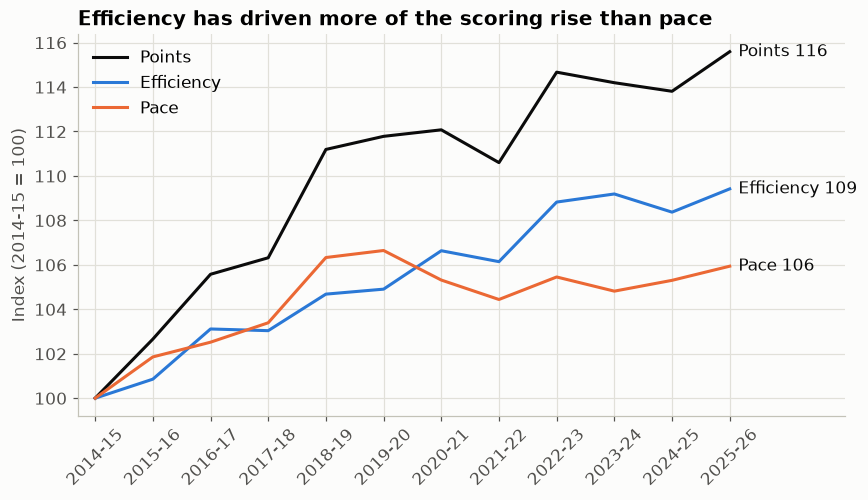

Share of the scoring increase from pace: 40%


In [10]:
series = [("PTS", "Points", INK), ("off_rating", "Efficiency", BLUE), ("pace", "Pace", ORANGE)]
indexed = league / league.iloc[0] * 100

fig, ax = plt.subplots()
for col, label, color in series:
    ax.plot(seasons, indexed[col], color=color, label=label)
    ax.text(11.15, indexed[col].iloc[-1], f"{label} {indexed[col].iloc[-1]:.0f}", va="center", color=INK)

ax.set_xlim(-0.3, 13)
ax.set_title("Efficiency has driven more of the scoring rise than pace")
ax.set_ylabel("Index (2014-15 = 100)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
plt.show()

first, last = league.iloc[0], league.iloc[-1]
share_from_pace = np.log(last["pace"] / first["pace"]) / np.log(last["PTS"] / first["PTS"])
print(f"Share of the scoring increase from pace: {share_from_pace:.0%}")

**What to notice**

- Points are up about 16%. Pace is up about 6% and efficiency about 9%, and those two multiply out to the rise in points.
- Pace explains about 40% of the increase, and efficiency the other 60%.
- Pace did most of its rising by 2018-19. Efficiency has kept climbing since, so **the reason scores rise may depend on which years you look at.** Indexing lets us see that on a single, honest axis.

### How do team-level stats relate to each other?

A correlation matrix is a quick map of which stats move together. Each row of this table is one team's average for one season.

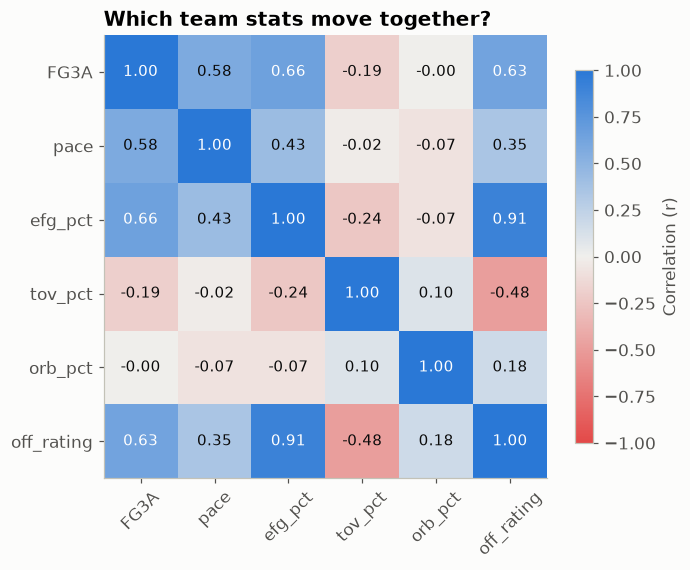

In [11]:
team_seasons = df.groupby(["season", "team_abbr"]).agg(
    FG3A=("FG3A", "mean"), pace=("pace", "mean"), efg_pct=("efg_pct", "mean"),
    tov_pct=("tov_pct", "mean"), orb_pct=("orb_pct", "mean"), off_rating=("off_rating", "mean"),
).reset_index()

columns = ["FG3A", "pace", "efg_pct", "tov_pct", "orb_pct", "off_rating"]
corr = team_seasons[columns].corr()

from matplotlib.colors import LinearSegmentedColormap
red_gray_blue = LinearSegmentedColormap.from_list("rgb", ["#e34948", "#f0efec", BLUE])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(corr, cmap=red_gray_blue, vmin=-1, vmax=1)
ax.set_xticks(range(6), columns, rotation=45)
ax.set_yticks(range(6), columns)
ax.grid(False)
for row in range(6):
    for col in range(6):
        value = corr.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else INK, fontsize=10)
ax.set_title("Which team stats move together?")
fig.colorbar(image, shrink=0.8, label="Correlation (r)")
plt.show()

`FG3A` and `off_rating` look strongly linked. But both have been rising over time, which could create a correlation even if one doesn't cause the other. Let's check.

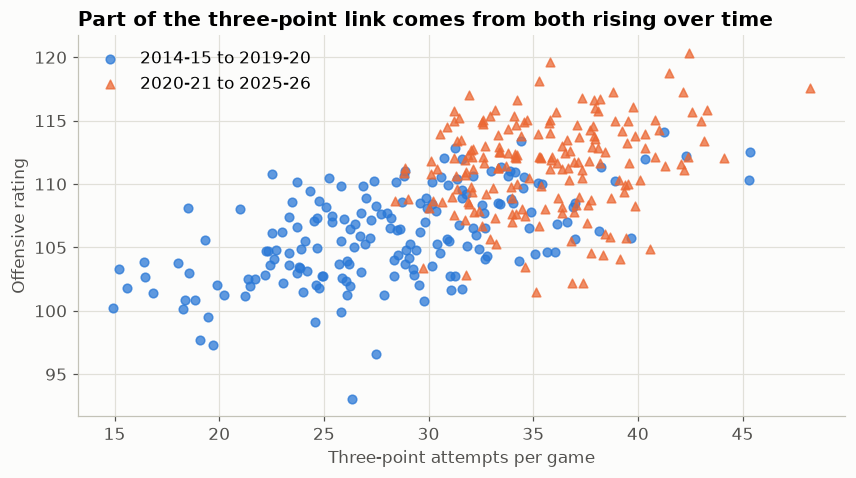

Correlation across all seasons pooled: 0.63
Average correlation within one season: 0.25


In [12]:
team_seasons["half"] = np.where(team_seasons["season"] <= "2019-20", "2014-15 to 2019-20", "2020-21 to 2025-26")

fig, ax = plt.subplots()
for half, color, marker in [("2014-15 to 2019-20", BLUE, "o"), ("2020-21 to 2025-26", ORANGE, "^")]:
    group = team_seasons[team_seasons["half"] == half]
    ax.scatter(group["FG3A"], group["off_rating"], color=color, marker=marker, s=32, alpha=0.75, label=half)

overall_r = team_seasons["FG3A"].corr(team_seasons["off_rating"])
within_r = team_seasons.groupby("season")[["FG3A", "off_rating"]].apply(lambda g: g["FG3A"].corr(g["off_rating"])).mean()

ax.set_title("Part of the three-point link comes from both rising over time")
ax.set_xlabel("Three-point attempts per game")
ax.set_ylabel("Offensive rating")
ax.legend(loc="upper left")
plt.show()

print(f"Correlation across all seasons pooled: {overall_r:.2f}")
print(f"Average correlation within one season: {within_r:.2f}")

**What to notice**

- Pooled together, r is about 0.63, which looks strong.
- Within a single season, it averages only about 0.25. Part of the pooled number is simply that both stats grew over the same decade.
- **When data spans many years, a shared trend can inflate a correlation.** Check within each period before drawing conclusions.

## 6. What should we ask next?

**What we learned**

- Three-point volume rose about 65% in 12 seasons, across the whole league.
- Scoring rose about 16%, with efficiency contributing more than pace.
- Our pace numbers run a steady 2-3 possessions above Basketball Reference's, so don't mix the two.

**Your turn**

1. `per_game.csv` goes back much further. Remake the pace and three-point charts over the full history. Where would you draw the line between eras?
2. Pick your era cutoffs and write down why. Do the conclusions change if you shift them by two years?
3. Does `q1_games_clean.csv` show matchup edges that last across eras? Start with its `edge` column, and use a histogram for each era.